# Regresión lineal múltiple y Ridge

Ejemplo para el curso de Inteligencia Artificial. Adaptado del ejemplo de https://github.com/krishnaik06/Multiple-Linear-Regression.

## 1. Descripción del problema y objetivo

Una empresa desea estimar las ganancias (Profit) de una startup a partir de sus gastos en investigación y desarrollo (R&D Spend), administración (Administration), marketing (Marketing Spend) y su ubicación (State). Cada fila del conjunto de datos 50_Startups representa una empresa.

Objetivo: construir y comparar dos modelos de regresión para predecir Profit, uno de regresión lineal múltiple y otro de regresión Ridge. Se evaluarán con datos que no se utilizaron para entrenarlos.

Las relaciones identificadas permiten hacer predicciones; no demuestran que un gasto cause directamente un cambio en las ganancias. El conjunto de datos es pequeño (50 empresas), por lo que sus resultados deben interpretarse con cautela.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## 2.Inspección inicial del conjunto de datos

Antes de entrenar cualquier modelo se revisan las dimensiones, los tipos de datos, las estadísticas descriptivas y la calidad básica de los registros.

In [21]:
df = pd.read_csv("50_Startups.csv")
print("Dimensiones (filas, columnas):", df.shape)
df.info()

Dimensiones (filas, columnas): (50, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


In [22]:
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
R&D Spend,50.0,NaN,NaN,NaN,73721.6156,45902.256482,0.0,39936.37,73051.08,101602.8,165349.2
Administration,50.0,NaN,NaN,NaN,121344.6396,28017.802755,51283.14,103730.875,122699.795,144842.18,182645.56
Marketing Spend,50.0,NaN,NaN,NaN,211025.0978,122290.310726,0.0,129300.1325,212716.24,299469.085,471784.1
State,50,3,New York,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profit,50.0,NaN,NaN,NaN,112012.6392,40306.180338,14681.4,90138.9025,107978.19,139765.9775,192261.83


### 2.1 Valores faltantes y registros duplicados

Se inspeccionan los valores ausentes y las filas repetidas. Si se encuentran registros problemáticos, conviene revisar su origen antes de eliminarlos o reemplazarlos.

In [4]:
print("Valores faltantes por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores faltantes por columna:
R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

Filas duplicadas: 0


El conjunto de datos contiene 50 registros de empresas y 5 variables. De estas, cuatro son numéricas (R&D Spend, Administration, Marketing Spend y Profit) y una es categórica (State), que presenta tres categorías: New York, California y Florida. La variable objetivo es Profit, mientras que las demás se utilizarán como variables predictoras.

El resultado de la función describe muestra diferencias importantes en las escalas y la dispersión de las variables numéricas. Por ejemplo, el gasto promedio en marketing es de aproximadamente 211.025, mientras que el gasto promedio en investigación y desarrollo es de 73.722. Las ganancias presentan un promedio de 112.013 y varían entre 14.681 y 192.262. También se observan valores mínimos de cero en los gastos de investigación y desarrollo y marketing, que conviene examinar posteriormente.

No se identificaron valores faltantes ni registros duplicados.

## 3. Exploración de la variable a predecir y las variables predictoras

La variable objetivo es Profit. Las variables numéricas predictoras son R&D Spend, Administration y Marketing Spend. State es categórica.

### 3.1 Distribución de la variable objetivo

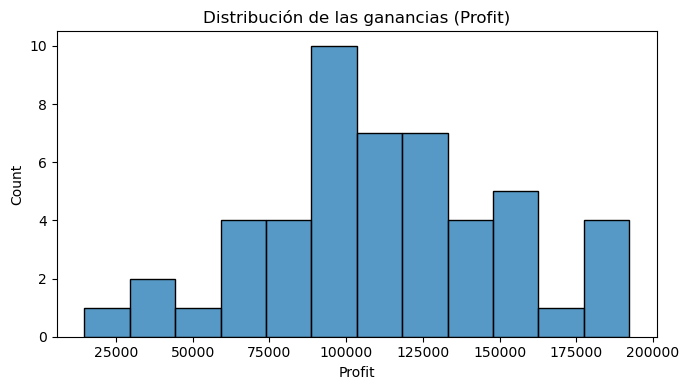

In [5]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Profit", bins=12)
plt.title("Distribución de las ganancias (Profit)")
plt.tight_layout()
plt.show()

### 3.2 Distribución de las variables predictoras

Para las variables numéricas se utilizan histogramas. Para State se utiliza un diagrama de barras con el número de empresas por estado.

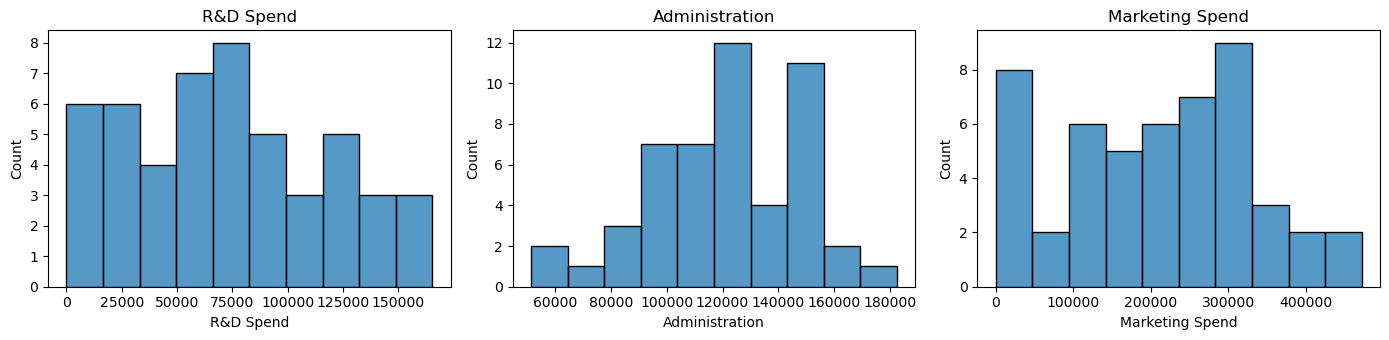

In [6]:
variables_numericas = ["R&D Spend", "Administration", "Marketing Spend"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, variable in zip(axes, variables_numericas):
    sns.histplot(data=df, x=variable, bins=10, ax=ax)
    ax.set_title(variable)
plt.tight_layout()
plt.show()

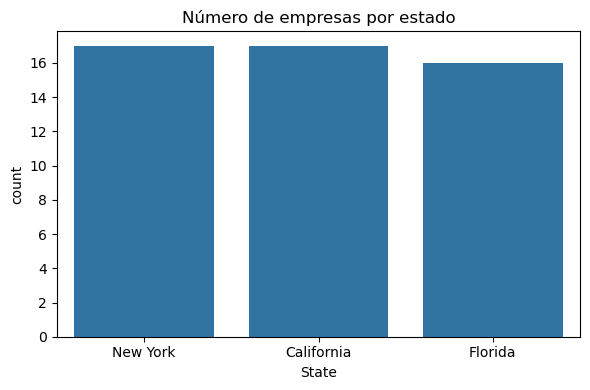

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="State")
plt.title("Número de empresas por estado")
plt.tight_layout()
plt.show()

### 3.3 Inspección de posibles valores atípicos

Los diagramas de cajas ayudan a detectar observaciones inusuales. Un valor señalado como atípico no es necesariamente incorrecto y no debe eliminarse automáticamente.

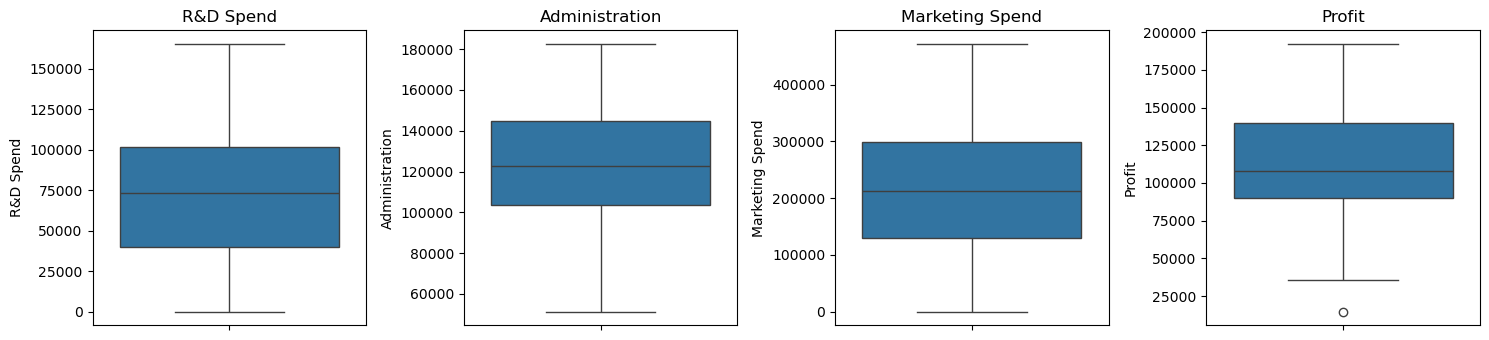

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, variable in zip(axes, variables_numericas + ["Profit"]):
    sns.boxplot(y=df[variable], ax=ax)
    ax.set_title(variable)
plt.tight_layout()
plt.show()

### 3.4 Correlación entre variables numéricas

Se utiliza la correlación de Pearson para explorar relaciones lineales, especialmente entre variables predictoras. Una correlación elevada entre predictores puede indicar multicolinealidad. La matriz sirve para explorar los datos, no para demostrar causalidad.

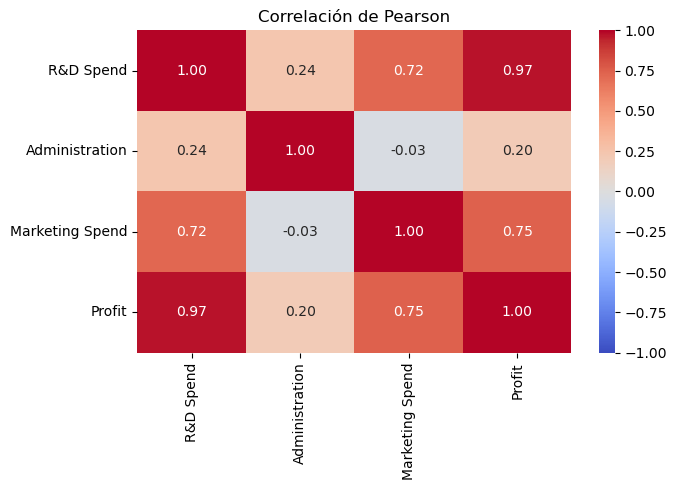

In [9]:
columnas_numericas = variables_numericas + ["Profit"]
correlaciones = df[columnas_numericas].corr(method="pearson")

plt.figure(figsize=(7, 5))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación de Pearson")
plt.tight_layout()
plt.show()

Los histogramas muestran que las ganancias (Profit) se concentran principalmente entre 90.000 y 140.000, aunque existen empresas con ganancias considerablemente menores o mayores. Las variables predictoras presentan distribuciones diferentes: R&D Spend y Marketing Spend muestran una dispersión amplia, incluyendo empresas con gastos iguales o cercanos a cero, mientras que Administration presenta una mayor concentración alrededor de sus valores centrales.

Los diagramas de cajas permiten identificar un posible valor atípico en la variable Profit, correspondiente a una empresa con ganancias particularmente bajas. Sin embargo, esta observación no debe eliminarse sin verificar previamente si corresponde a un error o a un caso válido.

El análisis de correlación de Pearson muestra que R&D Spend presenta la relación lineal más fuerte con Profit (r = 0.97), seguida de Marketing Spend (r = 0.75). Por el contrario, Administration presenta una correlación positiva débil con las ganancias (r = 0.20). Esto sugiere que los gastos en investigación y desarrollo podrían tener una mayor capacidad predictiva, aunque la correlación por sí sola no permite establecer relaciones causales ni determinar la contribución de cada variable en un modelo múltiple.

## 4. Preparación de datos

Se separan las variables predictoras de la variable objetivo y se reservan el 20 % de las empresas para prueba. El conjunto de prueba no se utiliza para ajustar el escalamiento ni para seleccionar hiperparámetros.

En este ejemplo no se realizará reducción ni selección de características: solo hay tres predictores numéricos y una variable categórica, y no se ha encontrado una justificación suficiente para eliminar alguno. La matriz de correlación por sí sola no obliga a descartar predictores.

In [10]:
X = df[variables_numericas + ["State"]].copy()
y = df["Profit"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0
)
print("Ejemplos de entrenamiento:", len(X_train))
print("Ejemplos de prueba:", len(X_test))

Ejemplos de entrenamiento: 40
Ejemplos de prueba: 10


### 4.1 Codificación de la variable categórica State

Los modelos de regresión requieren valores numéricos. Se convierten los estados en variables indicadoras (0 o 1); se omite una categoría de referencia para evitar una redundancia perfecta con el intercepto. Se definen las categorías con el conjunto de entrenamiento y se utiliza la misma estructura de columnas al transformar la prueba.

In [23]:
X_train_cod = pd.get_dummies(X_train, columns=["State"], dtype=int)
X_test_cod = pd.get_dummies(X_test, columns=["State"], dtype=int)
X_test_cod = X_test_cod.reindex(columns=X_train_cod.columns, fill_value=0)

X_train_cod.head()
print(X_train_cod.head())

    R&D Spend  Administration  Marketing Spend  State_California  \
33   55493.95       103057.49        214634.81                 0   
35   46014.02        85047.44        205517.64                 0   
26   75328.87       144135.98        134050.07                 0   
34   46426.07       157693.92        210797.67                 1   
18   91749.16       114175.79        294919.57                 0   

    State_Florida  State_New York  
33              1               0  
35              0               1  
26              1               0  
34              0               0  
18              1               0  


### 4.2 Estandarización de las variables numéricas

StandardScaler resta la media y divide por la desviación estándar. Se ajusta únicamente con las observaciones de entrenamiento y luego se aplica a entrenamiento y prueba. Solo se escalan las tres variables de gasto; las columnas de State permanecen como 0 o 1. Esta estandarización es especialmente útil para comparar el efecto de la regularización de Ridge.

In [24]:
scaler = StandardScaler()
X_train_preparado = X_train_cod.copy()
X_test_preparado = X_test_cod.copy()

X_train_preparado[variables_numericas] = scaler.fit_transform(X_train_cod[variables_numericas])
X_test_preparado[variables_numericas] = scaler.transform(X_test_cod[variables_numericas])

X_train_preparado.head()

,R&D Spend,Administration,Marketing Spend,State_California,State_Florida,State_New York
33,-0.350065,-0.785471,0.101197,0,1,0
35,-0.555303,-1.481174,0.027350,0,0,1
26,0.079358,0.801334,-0.551521,0,1,0
34,-0.546382,1.325058,0.070117,1,0,0
18,0.434854,-0.355987,0.751485,0,1,0


## 5. Implementación del modelo de regresión lineal múltiple

LinearRegression estima los coeficientes que minimizan la suma de errores cuadrados en los datos de entrenamiento.

In [13]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_preparado, y_train)

pred_lineal = modelo_lineal.predict(X_test_preparado)
print("Intercepto:", modelo_lineal.intercept_)
print("\nCoeficientes:")
print(pd.Series(modelo_lineal.coef_, index=X_train_preparado.columns))

Intercepto: 109441.48912163253

Coeficientes:
R&D Spend          35726.287742
Administration       851.301634
Marketing Spend     4519.882777
State_Florida       -959.284160
State_New York       699.369053
dtype: float64


### 5.1 Evaluación con el conjunto de prueba

Se calculan R², MAE y RMSE. MAE y RMSE se expresan en las mismas unidades de Profit; cuanto menores sean, mejor. R² puede ser negativo cuando el modelo funciona peor que predecir una constante igual a la media de la prueba.

In [27]:
def evaluar_modelo(valores_reales, predicciones):
    return {"R2": r2_score(valores_reales, predicciones), "MAE": mean_absolute_error(valores_reales, predicciones),
            "RMSE": np.sqrt(mean_squared_error(valores_reales, predicciones))}

In [28]:
metricas_lineal = evaluar_modelo(y_test, pred_lineal)
print(pd.Series(metricas_lineal).round(2))

R2         0.93
MAE     7514.29
RMSE    9137.99
dtype: float64


## 6. Implementación del modelo de regresión Ridge

Ridge es una regresión lineal que añade una penalización sobre el tamaño de los coeficientes. El hiperparámetro alpha controla la intensidad de la regularización: cuanto mayor sea, mayor será la penalización.

Para mantener la práctica sencilla, se entrenará Ridge con alpha=1. Este valor es ilustrativo: no se afirma que sea el óptimo. Si se prueban varios valores de alpha, no debe escogerse el mejor según el conjunto de prueba porque se dejaría de disponer de una evaluación independiente.

In [26]:
modelo_ridge = Ridge(alpha=1.0)
modelo_ridge.fit(X_train_preparado, y_train)

pred_ridge = modelo_ridge.predict(X_test_preparado)
metricas_ridge = evaluar_modelo(y_test, pred_ridge)
print(pd.Series(metricas_ridge).round(2))

R2         0.92
MAE     8018.49
RMSE    9947.36
dtype: float64


### 6.1 Exploración manual de alpha 

Para observar cómo cambia Ridge al aumentar la regularización, se entrenan modelos con distintos valores de alpha y se calcula su RMSE sobre el conjunto de entrenamiento. Este procedimiento es solo exploratorio: el menor error de entrenamiento no identifica necesariamente el mejor alpha para datos nuevos. No se modificará el modelo evaluado en prueba a partir de esta tabla.

In [30]:
resultados_alpha = []

for alpha in [0.1, 1, 10, 100]:
    modelo = Ridge(alpha=alpha)
    modelo.fit(X_train_preparado, y_train)

    pred_train = modelo.predict(X_train_preparado)
    metricas = evaluar_modelo(y_train, pred_train)

    resultados_alpha.append({"alpha": alpha, **metricas})

pd.DataFrame(resultados_alpha).round(2)

,alpha,R2,MAE,RMSE
0,0.1,0.95,6337.32,9032.61
1,1.0,0.95,6383.95,9110.84
2,10.0,0.92,8420.90,11572.41
3,100.0,0.60,19465.85,25660.44


## 7. Comparación de los resultados

En esta sección se comparan los resultados de la regresión lineal múltiple y la regresión Ridge utilizando el conjunto de prueba.

Para Ridge se utiliza alpha=0.1, que presentó el menor error de entrenamiento entre los valores explorados en la sección anterior. Esta selección tiene carácter exploratorio y no garantiza que sea el mejor valor para datos nuevos.

Ambos modelos se evaluarán utilizando las mismas observaciones de prueba y las métricas R², MAE y RMSE.

In [32]:
# Ridge con alpha=0.1
modelo_ridge = Ridge(alpha=0.1)
modelo_ridge.fit(X_train_preparado, y_train)

# Predicciones sobre el conjunto de prueba
pred_ridge = modelo_ridge.predict(X_test_preparado)

# Evaluación del modelo Ridge
metricas_ridge = evaluar_modelo(y_test, pred_ridge)

# Comparación con la regresión lineal
comparacion = pd.DataFrame([metricas_lineal, metricas_ridge], index=["Regresión lineal", "Ridge (alpha=0.1)"])

comparacion.round(2)

,R2,MAE,RMSE
Regresión lineal,0.93,7514.29,9137.99
Ridge (alpha=0.1),0.93,7557.65,9221.47


### 7.1 Valores reales frente a predichos

En un modelo perfecto los puntos quedarían sobre la diagonal. La comparación permite identificar predicciones alejadas de sus valores reales.

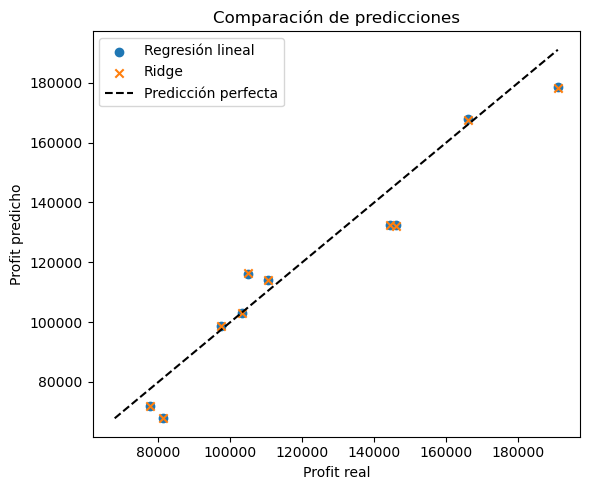

In [34]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred_lineal, label="Regresión lineal")
plt.scatter(y_test, pred_ridge, label="Ridge", marker="x")
limites = [min(y_test.min(), pred_lineal.min(), pred_ridge.min()),
           max(y_test.max(), pred_lineal.max(), pred_ridge.max())]
plt.plot(limites, limites, "k--", label="Predicción perfecta")
plt.xlabel("Profit real")
plt.ylabel("Profit predicho")
plt.title("Comparación de predicciones")
plt.legend()
plt.tight_layout()
plt.show()

### 7.2 Comparación de los valores reales y predichos

Se representan mediante gráficas de líneas los valores reales de Profit de las empresas del conjunto de prueba y los valores predichos por los modelos de regresión lineal y Ridge. El objetivo es observar visualmente qué tan próximas se encuentran las predicciones de ambos modelos a los valores reales e identificar aquellas observaciones donde presentan mayores errores.

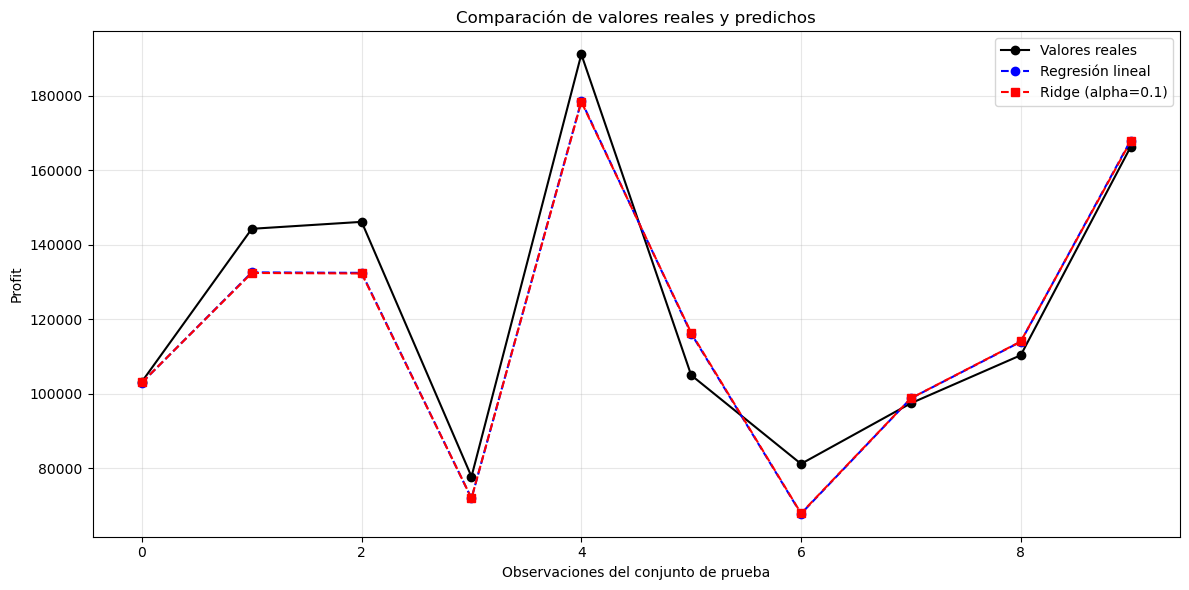

In [36]:
X = np.arange(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(X, np.array(y_test), 'k-o',label='Valores reales')
plt.plot(X, pred_lineal, 'b--o', label='Regresión lineal')
plt.plot(X, pred_ridge, 'r--s',label='Ridge (alpha=0.1)')
plt.xlabel('Observaciones del conjunto de prueba')
plt.ylabel('Profit')
plt.title('Comparación de valores reales y predichos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Interpretación y conclusiones

Los resultados sobre el conjunto de prueba muestran que ambos modelos presentan un rendimiento predictivo similar, con un coeficiente de determinación R² de aproximadamente 0.93. Esto indica que ambos explican alrededor del 93 % de la variabilidad de las ganancias en las observaciones de prueba.

La regresión lineal múltiple presenta errores ligeramente menores, con un MAE de 7.514,29 y un RMSE de 9.137,99, frente a 7.557,65 y 9.221,47 obtenidos por Ridge con alpha=0.1.

Aunque Ridge incorpora regularización para reducir la magnitud de los coeficientes y controlar el sobreajuste, en este experimento no produjo una mejora en la capacidad predictiva respecto a la regresión lineal ordinaria.

Por tanto, para este conjunto de datos y esta división entre entrenamiento y prueba, la regresión lineal múltiple constituye la alternativa más sencilla y presenta resultados ligeramente mejores. Sin embargo, dado que el conjunto de datos contiene solamente 50 observaciones, estos resultados pueden variar si se utiliza una partición diferente.

En conclusión, el experimento muestra que incorporar regularización no garantiza obtener mejores predicciones. Su utilidad depende de las características de los datos, la complejidad del modelo y la intensidad de regularización seleccionada.